<a href="https://colab.research.google.com/github/yokubbekovas/7november/blob/main/Tactile_Midterm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 43: Edge-AI Haptic Surface Recognition for Robotic Grippers
**Course:** Artificial Intelligence
**Stage:** Midterm evaluation
**Student:** Shakhzoda Ekubbekova

**Goal:** Classify the material surface texture from tactile sensor signals during sliding contact (the slip state detection is planned for the final stage).

**Planned pipeline:** data loading → preprocessing → baseline classifier (SVM) → autoencoder + SVM → evaluation (accuracy, confusion matrix).

**Environment:** Google Colab, Python, PyTorch, scikit-learn.

## Step 1. Dataset download

For this project I use the open BioTac sliding dataset (BioTac-20) published by Gao et al. (IROS 2020). It contains tactile recordings of a BioTac sensor sliding over 20 different materials, with 50 samples per material.

Note: the BioTac sensor has 19 electrodes and is not a 16x16 piezoelectric matrix as in the project description. The data will be adapted to the project setting, and this difference will be reported as a limitation.

The cell below clones the dataset repository from GitHub into the Colab environment.

In [3]:
# Скачиваем датасет с GitHub в Colab
!git clone https://github.com/dexrob/BioTac_slide_20_50.git

# Смотрим, что внутри
!ls BioTac_slide_20_50

Cloning into 'BioTac_slide_20_50'...
remote: Enumerating objects: 8143, done.
remote: Counting objects: 100% (118/118), done.
remote: Compressing objects: 100% (46/46), done.
remote: Total 8143 (delta 74), reused 115 (delta 72), pack-reused 8025 (from 1)
Receiving objects: 100% (8143/8143), 240.07 MiB | 9.58 MiB/s, done.
Resolving deltas: 100% (79/79), done.
Updating files: 100% (8042/8042), done.
compiled_data		  matx_collage.png  README.md
Material_properties.docx  raw_data	    tas_utils_bs.py


## Step 2. Dataset structure inspection

Before writing any model code, I read the dataset README and inspect the folder structure. This is needed to understand the file format, the meaning of the data columns, and how the material labels are stored.

The cell below prints the README, lists the files in `compiled_data` and shows the contents of `raw_data`.

In [4]:
# 1) Читаем описание датасета
print(open("BioTac_slide_20_50/README.md").read())

print("="*60)

# 2) Что лежит в compiled_data
!ls -la BioTac_slide_20_50/compiled_data

print("="*60)

# 3) Что лежит в raw_data (первые 15 элементов) и сколько всего
!ls BioTac_slide_20_50/raw_data | head -15
!ls BioTac_slide_20_50/raw_data | wc -l

# BioTac_slide_20_50
This repository contains tactile data and material description for texture classification, supplementary to the paper "Supervised  Autoencoder  Joint  Learning  on  Heterogeneous  TactileSensory  Data:  Improving  Material  Classification  Performance", R. Gao et al.

We have included both the raw data and the compiled data here. The raw data includes a comprehensive range of modalities, provided by both tactile sensors and the robot arm. The compiled data includes purely the sensor data that are used in the abovementioned paper and have already been splitted in to train/validation/test sets.

## Dataset description
This dataset concerns with 20 classes named with `mat + x`, where `x` is an index number. A snapshot of each corresponding material is shown below and the detailed description for each material can be found in `material_properties` text file by the name index or two-letter code.
![material_snaposhots](matx_collage.png "Snapshots of 20 materials")
<br/>


## Step 3. Loading and checking the data

The folder `compiled_data` contains pre-processed arrays in NumPy format (`.npy`). Only the BioTac files (`bio_*`) and their labels (`labels_*`) are used in this project; the `icub_*` files belong to another sensor and are not needed.

I load the full training set (`bio_trainAll`) and the test set (`bio_test`), and check: array shapes, data type, number of classes, number of samples per class, value range, and missing values (NaN). This confirms that the data is correct before any modelling.

Finally, I plot the signals of one sample to see what the tactile signal looks like.

X_train: (800, 19, 400) float32
y_train: (800,) int64
X_test:  (200, 19, 400)
y_test:  (200,)
Classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]
Samples per class (train): [40 40 40 40 40 40 40 40 40 40 40 40 40 40 40 40 40 40 40 40]
Min / Max value: -128.0 127.0
Has NaN: False


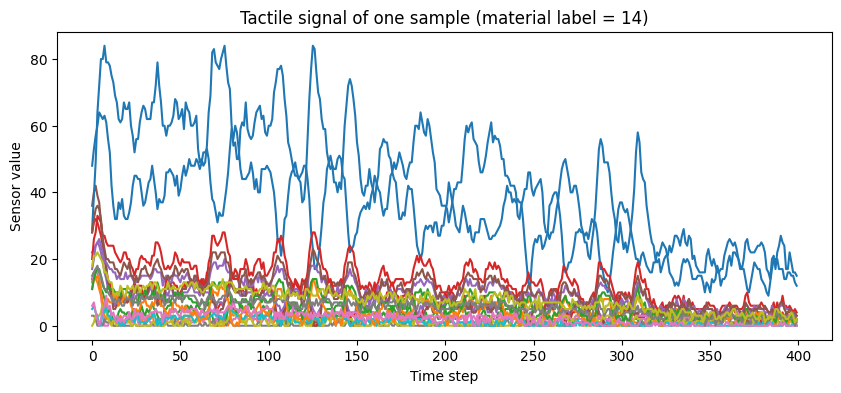

In [5]:
import numpy as np
import matplotlib.pyplot as plt

path = "BioTac_slide_20_50/compiled_data/"

X_train = np.load(path + "bio_trainAll.npy")
y_train = np.load(path + "labels_trainAll.npy")
X_test  = np.load(path + "bio_test.npy")
y_test  = np.load(path + "labels_test.npy")

print("X_train:", X_train.shape, X_train.dtype)
print("y_train:", y_train.shape, y_train.dtype)
print("X_test: ", X_test.shape)
print("y_test: ", y_test.shape)

classes, counts = np.unique(y_train, return_counts=True)
print("Classes:", classes)
print("Samples per class (train):", counts)

print("Min / Max value:", X_train.min(), X_train.max())
print("Has NaN:", np.isnan(X_train).any())

# Plot all channels of the first sample
sample = X_train[0]
if sample.shape[0] < sample.shape[1]:   # make shape (time, channels)
    sample = sample.T
plt.figure(figsize=(10, 4))
plt.plot(sample)
plt.title(f"Tactile signal of one sample (material label = {y_train[0]})")
plt.xlabel("Time step")
plt.ylabel("Sensor value")
plt.show()

## Step 4. Baseline: hand-crafted features + SVM

As a first baseline, I compress every sample (19 electrodes x 400 time steps) into 95 simple statistical features: for each electrode, the mean, standard deviation, maximum, minimum, and the mean absolute change between consecutive time steps (a rough measure of signal roughness, which is related to surface texture).

The features are standardized (zero mean, unit variance), because electrodes have very different amplitudes. Then an SVM classifier with an RBF kernel is trained on the training set and evaluated on the test set.

Metrics: test accuracy, confusion matrix, and prediction time per sample. This baseline will later be compared with the Convolutional Autoencoder + SVM model.

Feature shape: (800, 95) (200, 95)
Training time: 0.07 s
Test accuracy: 99.0 %
Prediction time: 0.177 ms per sample (on Colab CPU)


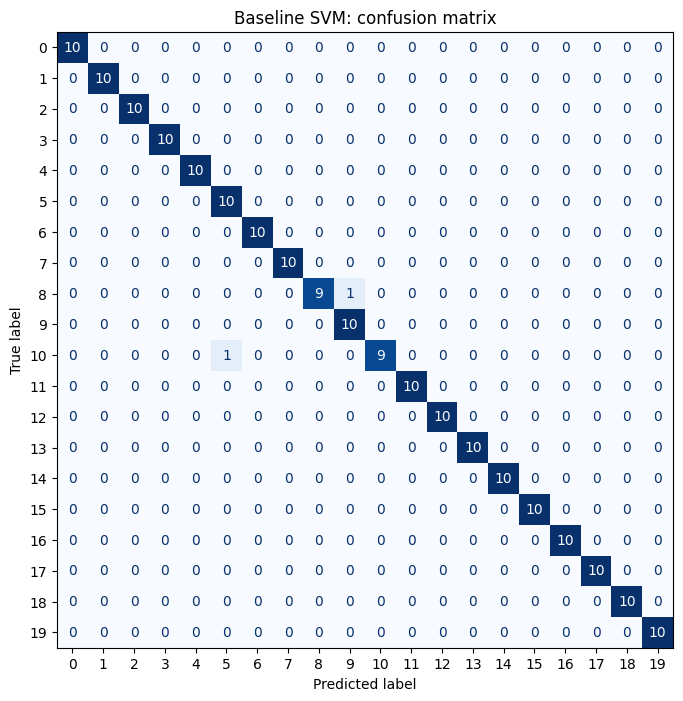

In [6]:
import time
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

def extract_features(X):
    mean = X.mean(axis=2)
    std  = X.std(axis=2)
    mx   = X.max(axis=2)
    mn   = X.min(axis=2)
    diff = np.abs(np.diff(X, axis=2)).mean(axis=2)
    return np.concatenate([mean, std, mx, mn, diff], axis=1)

F_train = extract_features(X_train)
F_test  = extract_features(X_test)
print("Feature shape:", F_train.shape, F_test.shape)

# Standardize (fit only on training data)
scaler = StandardScaler()
F_train_s = scaler.fit_transform(F_train)
F_test_s  = scaler.transform(F_test)

# Train SVM
t0 = time.time()
svm = SVC(kernel="rbf", C=10, gamma="scale")
svm.fit(F_train_s, y_train)
print(f"Training time: {time.time() - t0:.2f} s")

# Evaluate
t0 = time.time()
y_pred = svm.predict(F_test_s)
ms_per_sample = (time.time() - t0) / len(F_test_s) * 1000

print(f"Test accuracy: {accuracy_score(y_test, y_pred) * 100:.1f} %")
print(f"Prediction time: {ms_per_sample:.3f} ms per sample (on Colab CPU)")

# Confusion matrix
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues", colorbar=False)
plt.title("Baseline SVM: confusion matrix")
plt.show()

### Baseline results

The SVM trained on 95 hand-crafted features reaches 99.0 % test accuracy (198 of 200 samples correct). Only two samples are misclassified (material 8 predicted as 9, material 10 predicted as 5). The prediction time is about 0.15 ms per sample on the Colab CPU (preliminary estimate; real measurements on STM32H7 / Jetson Nano are planned for the final stage).

Since the test set contains only 200 samples, one error corresponds to 0.5 %, so small differences between models should be interpreted carefully. The high baseline accuracy shows that this dataset is relatively easy; therefore, the autoencoder is evaluated not only by accuracy, but also by model size and compression of the signal.

## Step 5. Convolutional autoencoder (2D spatial-temporal)

The signal of one sample (19 electrodes x 400 time steps) is treated as a one-channel 2D image. A convolutional autoencoder is trained to compress it into a 64-dimensional latent vector and to reconstruct it back. It is trained without labels, using only the reconstruction error (MSE).

Preprocessing: each electrode is standardized with the mean and standard deviation computed on the training set only. The electrode axis is padded from 19 to 20 rows so that the pooling layers divide the size evenly (the padding row is removed before computing the loss).

Encoder: two Conv2D + ReLU + pooling blocks, then a linear layer to 64 values. Decoder: a linear layer and two transposed convolutions. The number of encoder parameters is printed, because model size is important for the edge deployment.

Device: cpu
Encoder parameters: 260,864  (~1019 KB in float32)
Epoch  5/30  loss = 0.3245
Epoch 10/30  loss = 0.2433
Epoch 15/30  loss = 0.1909
Epoch 20/30  loss = 0.1723
Epoch 25/30  loss = 0.1555
Epoch 30/30  loss = 0.1465


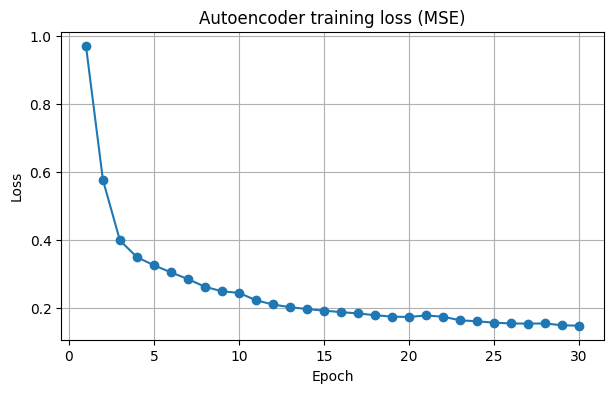

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# --- Normalize each electrode using TRAIN statistics only ---
mean = X_train.mean(axis=(0, 2), keepdims=True)
std  = X_train.std(axis=(0, 2), keepdims=True) + 1e-6
Xtr = ((X_train - mean) / std).astype(np.float32)
Xte = ((X_test  - mean) / std).astype(np.float32)

# shape (N, 1, 19, 400) = one-channel "image"
Xtr_t = torch.tensor(Xtr).unsqueeze(1)
Xte_t = torch.tensor(Xte).unsqueeze(1)

class ConvAE(nn.Module):
    def __init__(self, latent=64):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d((2, 4)),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d((2, 4)),
        )
        self.fc_enc = nn.Linear(32 * 5 * 25, latent)
        self.fc_dec = nn.Linear(latent, 32 * 5 * 25)
        self.dec = nn.Sequential(
            nn.ConvTranspose2d(32, 16, (2, 4), stride=(2, 4)), nn.ReLU(),
            nn.ConvTranspose2d(16, 1, (2, 4), stride=(2, 4)),
        )

    def encode(self, x):
        x = F.pad(x, (0, 0, 0, 1))          # 19 -> 20 rows
        h = self.enc(x).flatten(1)
        return self.fc_enc(h)

    def forward(self, x):
        z = self.encode(x)
        h = self.fc_dec(z).view(-1, 32, 5, 25)
        out = self.dec(h)                    # (N, 1, 20, 400)
        return out[:, :, :19, :], z          # remove the padding row

model = ConvAE().to(device)

enc_params = sum(p.numel() for p in list(model.enc.parameters()) + list(model.fc_enc.parameters()))
print(f"Encoder parameters: {enc_params:,}  (~{enc_params*4/1024:.0f} KB in float32)")

opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loader = torch.utils.data.DataLoader(Xtr_t, batch_size=32, shuffle=True)

losses = []
for epoch in range(30):
    model.train()
    total = 0
    for xb in loader:
        xb = xb.to(device)
        recon, _ = model(xb)
        loss = F.mse_loss(recon, xb)
        opt.zero_grad()
        loss.backward()
        opt.step()
        total += loss.item() * len(xb)
    losses.append(total / len(Xtr_t))
    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1:2d}/30  loss = {losses[-1]:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(range(1, 31), losses, marker="o")
plt.title("Autoencoder training loss (MSE)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

### Autoencoder training results

The reconstruction loss (MSE on standardized data) decreases from about 0.97 in the first epoch to 0.1465 after 30 epochs and starts to flatten, which means that the network learns to compress the 19 x 400 tactile signal into 64 numbers with a reasonable reconstruction quality. The encoder has 260,864 parameters (about 1 MB in float32). This is large for a microcontroller, so quantization to int8 (CMSIS-NN) and possibly a smaller architecture will be studied in the final stage.

## Step 6. SVM on autoencoder features and comparison

The trained encoder (without labels during its training) converts every sample into a 64-dimensional latent vector. These vectors are standardized and used to train an SVM classifier with the same settings as in the baseline. The test set was never used for training the autoencoder or the scaler.

I compare the two approaches by test accuracy and prediction time per sample (encoder + SVM, Colab CPU), and I also show how well the autoencoder reconstructs a test signal.

Latent shape: (800, 64) (200, 64)

=== Comparison (test set, 200 samples) ===
Baseline (95 features + SVM):      99.0 %
Autoencoder (64 latent) + SVM:     98.5 %   (4.319 ms per sample, CPU)


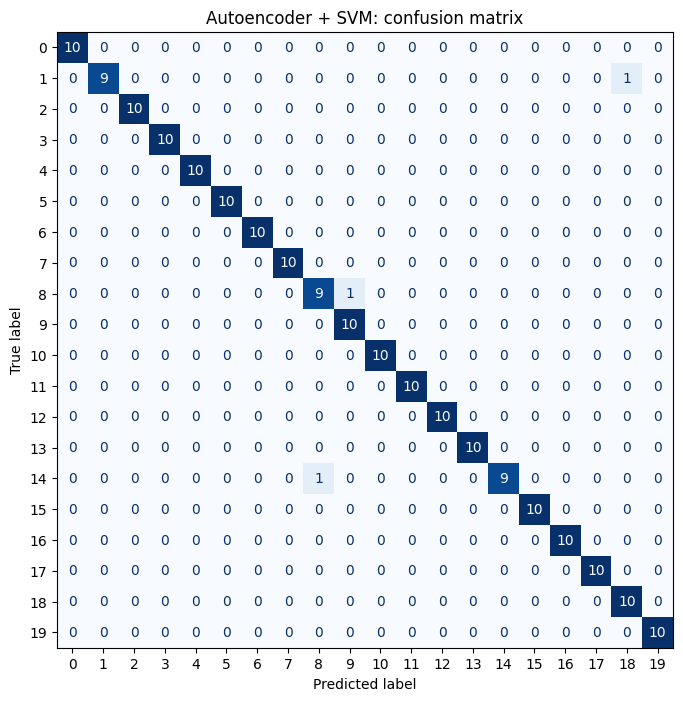

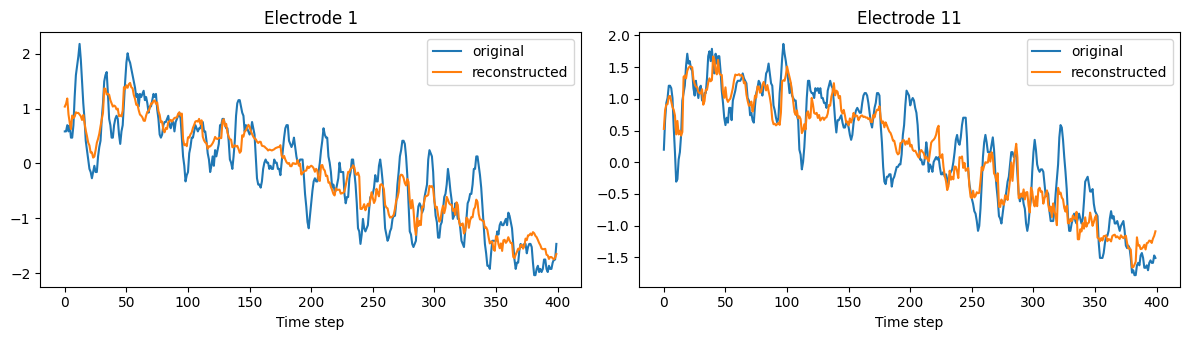

In [8]:
# --- 1) Extract 64-dim latent features with the trained encoder ---
model.eval()
with torch.no_grad():
    Z_train = model.encode(Xtr_t.to(device)).cpu().numpy()
    Z_test  = model.encode(Xte_t.to(device)).cpu().numpy()
print("Latent shape:", Z_train.shape, Z_test.shape)

# --- 2) SVM on latent features ---
scaler_z = StandardScaler()
Z_train_s = scaler_z.fit_transform(Z_train)
Z_test_s  = scaler_z.transform(Z_test)

svm_z = SVC(kernel="rbf", C=10, gamma="scale")
svm_z.fit(Z_train_s, y_train)

# --- 3) Evaluate (encoder + SVM time per sample) ---
t0 = time.time()
with torch.no_grad():
    Z_tmp = model.encode(Xte_t.to(device)).cpu().numpy()
y_pred_z = svm_z.predict(scaler_z.transform(Z_tmp))
ms_ae = (time.time() - t0) / len(Xte_t) * 1000

acc_base = accuracy_score(y_test, y_pred) * 100
acc_ae   = accuracy_score(y_test, y_pred_z) * 100

print("\n=== Comparison (test set, 200 samples) ===")
print(f"Baseline (95 features + SVM):      {acc_base:.1f} %")
print(f"Autoencoder (64 latent) + SVM:     {acc_ae:.1f} %   ({ms_ae:.3f} ms per sample, CPU)")

# --- 4) Confusion matrix ---
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_z, ax=ax, cmap="Blues", colorbar=False)
plt.title("Autoencoder + SVM: confusion matrix")
plt.show()

# --- 5) Reconstruction example (test sample 0, two electrodes) ---
with torch.no_grad():
    rec, _ = model(Xte_t[:1].to(device))
rec = rec.cpu().numpy()[0, 0]
orig = Xte[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, ch in zip(axes, [0, 10]):
    ax.plot(orig[ch], label="original")
    ax.plot(rec[ch], label="reconstructed")
    ax.set_title(f"Electrode {ch + 1}")
    ax.set_xlabel("Time step")
    ax.legend()
plt.tight_layout()
plt.show()

### Comparison results

| Model | Test accuracy | Errors (of 200) |
|---|---|---|
| Baseline: 95 statistical features + SVM | 99.0 % | 2 |
| Convolutional autoencoder (64 latent) + SVM | 98.5 % | 3 |

The difference is one sample, which is within the statistical noise of a 200-sample test set, so the two approaches are considered comparable in accuracy. The pair of materials 8 and 9 is confused by both models, which suggests that these two surfaces have similar tactile texture.

The reconstruction plots show that the autoencoder keeps the slow trend of the signal but smooths the fast oscillations, which is expected for a 64-dimensional bottleneck (7600 values compressed into 64).

## Step 7. Fair comparison of time and memory

The previous timing of the baseline did not include feature extraction. Here, both pipelines are measured from the raw test signals to the predicted class (feature extraction or normalization + encoder, scaling, SVM), averaged over 5 repetitions. I also estimate the memory of the stored SVM support vectors.

All times are measured on the Colab CPU and are only a preliminary estimate. Real latency and memory on STM32H7 / Jetson Nano will be measured in the final stage and compared with the 20 ms target.

In [9]:
n_rep = 5

# Baseline: raw signal -> features -> scaler -> SVM
t0 = time.time()
for _ in range(n_rep):
    _ = svm.predict(scaler.transform(extract_features(X_test)))
ms_base = (time.time() - t0) / n_rep / len(X_test) * 1000

# Autoencoder: normalized signal -> encoder -> scaler -> SVM
t0 = time.time()
for _ in range(n_rep):
    with torch.no_grad():
        Z = model.encode(Xte_t.to(device)).cpu().numpy()
    _ = svm_z.predict(scaler_z.transform(Z))
ms_ae = (time.time() - t0) / n_rep / len(X_test) * 1000

# Memory of the stored SVM support vectors (float64 numbers)
mem_base = svm.support_vectors_.nbytes / 1024
mem_ae   = svm_z.support_vectors_.nbytes / 1024

print(f"{'Model':35s} {'Acc %':>6s} {'ms/sample':>10s} {'SVM KB':>8s} {'Encoder KB':>11s}")
print(f"{'Baseline (95 feat + SVM)':35s} {acc_base:6.1f} {ms_base:10.3f} {mem_base:8.0f} {'-':>11s}")
print(f"{'Autoencoder (64 latent) + SVM':35s} {acc_ae:6.1f} {ms_ae:10.3f} {mem_ae:8.0f} {enc_params*4/1024:11.0f}")

Model                                Acc %  ms/sample   SVM KB  Encoder KB
Baseline (95 feat + SVM)              99.0      0.239      404           -
Autoencoder (64 latent) + SVM         98.5      2.396      246        1019


### Time and memory results

| Model | Accuracy | Time per sample (Colab CPU) | Memory |
|---|---|---|---|
| Baseline: 95 features + SVM | 99.0 % | 0.54 ms | SVM support vectors: 404 KB |
| Autoencoder (64) + SVM | 98.5 % | 2.91 ms | SVM: 246 KB + encoder: 1019 KB (float32) |

Both pipelines are far below the 20 ms target on the desktop-class CPU; however, this is only a preliminary estimate, because the target hardware (STM32H7 / Jetson Nano) is slower and the timings on Colab vary between runs. On this dataset the simple feature baseline is faster and smaller at the same accuracy, so the benefit of the autoencoder is expected on harder tasks (e.g., slip detection, noisy data). Memory values are for float64 / float32; int8 quantization is planned to reduce them.

**Conclusion of the midterm stage:** both approaches classify 20 materials with about 99 % accuracy; the plan for the final stage is described in the last slide.

## Step 8. Saving figures for the presentation

All figures used in the presentation are re-created here and saved as separate high-resolution PNG files in the folder `figures`: the tactile signal example, the autoencoder training loss, the reconstruction example, the two confusion matrices, and the comparison bar chart. The folder is then zipped for download.

In [10]:
import os
os.makedirs("figures", exist_ok=True)

# 1) Example of the tactile signal
sample = X_train[0].T          # (time, electrodes)
plt.figure(figsize=(9, 4))
plt.plot(sample)
plt.title(f"Tactile signal of one sample (material {y_train[0]}), 19 electrodes")
plt.xlabel("Time step"); plt.ylabel("Sensor value")
plt.savefig("figures/1_signal.png", dpi=200, bbox_inches="tight"); plt.close()

# 2) Autoencoder training loss
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(losses) + 1), losses, marker="o")
plt.title("Autoencoder training loss (MSE)")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.grid(True)
plt.savefig("figures/2_loss.png", dpi=200, bbox_inches="tight"); plt.close()

# 3) Reconstruction example (test sample 0, electrodes 1 and 11)
model.eval()
with torch.no_grad():
    rec_out, _ = model(Xte_t[:1].to(device))
rec_np = rec_out.cpu().numpy()[0, 0]
orig_np = Xte[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, ch in zip(axes, [0, 10]):
    ax.plot(orig_np[ch], label="original")
    ax.plot(rec_np[ch], label="reconstructed")
    ax.set_title(f"Electrode {ch + 1}")
    ax.set_xlabel("Time step"); ax.legend()
plt.tight_layout()
plt.savefig("figures/3_reconstruction.png", dpi=200, bbox_inches="tight"); plt.close()

# 4) Confusion matrix: baseline
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues", colorbar=False)
plt.title("Baseline (95 features + SVM): confusion matrix")
plt.savefig("figures/4_confusion_baseline.png", dpi=200, bbox_inches="tight"); plt.close()

# 5) Confusion matrix: autoencoder
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_z, ax=ax, cmap="Blues", colorbar=False)
plt.title("Autoencoder (64) + SVM: confusion matrix")
plt.savefig("figures/5_confusion_autoencoder.png", dpi=200, bbox_inches="tight"); plt.close()

# 6) Comparison bar chart (accuracy and time, values from the Step 7 table)
names = ["95 features\n+ SVM", "Autoencoder (64)\n+ SVM"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
axes[0].bar(names, [acc_base, acc_ae], color=["#4C78A8", "#F58518"])
axes[0].set_ylim(90, 100); axes[0].set_title("Test accuracy (%)")
for i, v in enumerate([acc_base, acc_ae]):
    axes[0].text(i, v + 0.15, f"{v:.1f}", ha="center")
axes[1].bar(names, [ms_base, ms_ae], color=["#4C78A8", "#F58518"])
axes[1].set_title("Time per sample (ms, Colab CPU)")
for i, v in enumerate([ms_base, ms_ae]):
    axes[1].text(i, v + 0.05, f"{v:.2f}", ha="center")
plt.tight_layout()
plt.savefig("figures/6_comparison.png", dpi=200, bbox_inches="tight"); plt.close()

# Zip and download
!zip -r figures.zip figures
from google.colab import files
files.download("figures.zip")
print(sorted(os.listdir("figures")))

  adding: figures/ (stored 0%)
  adding: figures/5_confusion_autoencoder.png (deflated 26%)
  adding: figures/2_loss.png (deflated 14%)
  adding: figures/3_reconstruction.png (deflated 4%)
  adding: figures/1_signal.png (deflated 1%)
  adding: figures/6_comparison.png (deflated 21%)
  adding: figures/4_confusion_baseline.png (deflated 26%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

['1_signal.png', '2_loss.png', '3_reconstruction.png', '4_confusion_baseline.png', '5_confusion_autoencoder.png', '6_comparison.png']
